# Bayesian Analysis with Python - Part 1

## Introduction

This is an acccount of my adventures with trying (yet again) to get into Bayesian statistics.  I decided that dabbling was counter-productive, so got a paper copy of __Bayesian Analysis with Python: A practical guide to probabilistic modeling (Edition 3)__
by Osvaldo Martin, and decided to work through the book (which I recommend)

## Discoveries

First up, the book specifies a conda environment with a set of packages at very specific version numbers (most now not the latest, even though the book was published in 2024).  I decided to be brave, and install the packages discussed in the book at their latest revision levels.

This was indeed a brave decision it turns out, because one of the key packages __ArviZ__, has changed so much since the book was published, that there is a migration guide (https://python.arviz.org/en/stable/user_guide/migration_guide.html).  Be sure you are reading the  documentation that matches  the version of the packages you install, because there have been changes! 

Also, be sure to read __Exploratory Analysis of Bayesian Models__ (https://arviz-devs.github.io/EABM/). To quote the migration guide:

    One recurring feedback we have received is that the documentation was OK for people very familiar with Bayesian statistics and probabilistic programming, but not so much for newcomers. Thus, we have added more introductory material and examples to the documentation, including a separated resource that show how to use ArviZ “in-context”, see EABM. 

I decided to push on to learn to use the latest libraries.  In some ways, this was good, as I had to understand replacement functions and parameters to write code myself, rather than cut and paste from the book.  The migration guide does contain a helpful mapping from deprecated or removed functions , to the latest substitutes

------------------

### History of _conda install_ operations

This section contains a history (to date) on how I set up my environment (using conda).

#### Initial install

I decided to use __conda-forge__ for the source of all packages (hoping for inter-package consistency). I also decided to go with the latest Python, even though the book uses an earlier version

    conda-script.py create --name bayes_env python=3.14 pymc arviz bambi pymc-bart preliz nutpie -c conda-forge

#### Install of Jupyter Lab notebooks

My preferred way the write exploratory code. __black__ and __watermark__ provide formatting and internal versioning respectively

    conda-script.py install -c conda-forge black watermark jupyterlab isort ipynbname

#### Install of _netcdf_ packages

I didn't get very far before I saw complaints that _netcdf_ support was missing.  Using the default __conda__ channel gave some weird results; __aws__ packages were pulled (don't know why):  __--dry-run__ is your friend when using __conda__ to create an environment!

    conda-script.py install netcdf4 -c conda-forge

    conda-script.py install h5netcdf -c conda-forge

#### Jupyter Lab notebook formatting

    conda-script.py install jupyterlab_code_formatter -c conda-forge

#### _scipy_ version reset

There were errors arising from a mismatch between the _scipy_ compiled C library, and the Bayesian analysis packages.  The recommendation was to downgrade the _scipy_ library.  The hypothesis is that the _scipy_ library was recently enhanced, and _ArviZ_ has yet to catch up.

    conda-script.py install scipy<1.18.0 -c conda-forge

#### Jupyter UI enhancements

The Bayesian analysis packages show progress with progress-bars, which need _ipwidgets_

    conda-script.py install ipywidgets -c conda-forge

#### PyTensor configuration

PyTensor has a mode of operation where it builds a C routine for efficient modelling, which it then complies and executes.  I had problems with this mode (I suspect that somewhere in my PC I already have some libraries installed outside of __conda__, but on my _PATH_, that don't mesh well with PyTensor.

Effectively I turned off the "comple and execute" mode by:

    pytensor.config.cxx = ""

-------------------

## Implementation
#### Imports

    "PreliZ is a Python package aimed at helping practitioners choose prior distributions by offering a set of tools for the various facets of prior elicitation."

    "ArviZ is a modular and flexible Python library implementing methods ... providing robust, interpretable diagnostics and visualizations for Bayesian workflow"

    "PyMC is a probabilistic programming library for Python that allows users to build Bayesian models with a simple Python API"

    "PyTensor is a Python library that allows you to define, optimize/rewrite, and evaluate mathematical expressions involving multi-dimensional arrays efficiently"

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import preliz as pz
import pymc as pm
import pytensor

import numpy as np

### using PreliZ

This initial section is setting up to peform the classic Bayesian analysis of tossing a coin to estimate the bias of the coin (i.e. what is the value of $p$, the probability of a head on a single toss.  The coin toss is modelled as a Binomial process (each toss is independent, each has the same $p$ value)

We will adopt the Beta distribution as our prior (i.e. our initial guess as the coin's bias).  Use of the Beta allows an analytic solution that we can compare to our probabilistic solution.  The Beta distribution can be adjusted to give a flat shape (i.e. no strong expectation of any bias value), or shapes that reflect a prior belief in Head (or Tail) bias

In [2]:
# set the probability of getting a head (i,e, coin is biased to tails
p_true = 0.35

#### Plotting distribution

Initially we use _matplotlib_ to create a plotting environment.  It is  more compact to have the legend where the  title usually goes 

    legend="title",

We also ask for the High Density Intervals to be shown (i.e. the shortest intervals that contain 50% and 94% of the probability)
    

<Axes: title={'center': 'Binomial(n=4, p=0.35)'}>

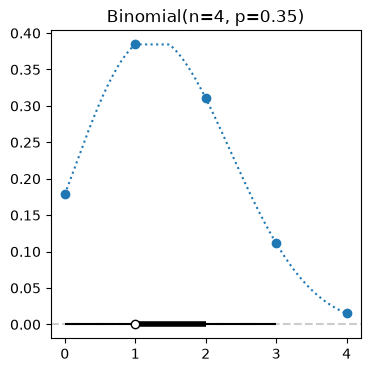

In [3]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4, 4))

pz.distributions.binomial.Binomial(
    n=4,
    p=p_true,
).plot_pdf(
    ax=ax,
    interval="hdi",
    pointinterval=True,
    legend="title",
)

### Get high density intervals

We get the 50% and 94% intervals

We see that they match the plot above

In [4]:
pz.distributions.binomial.Binomial(
    n=4,
    p=p_true,
).hdi(mass=0.5)

(1, 2)

In [5]:
pz.distributions.binomial.Binomial(
    n=4,
    p=p_true,
).hdi(mass=0.94)

(0, 3)

#### Internal plotting

PreliZ also has an interval plotting mode (not needing any _matplotlib_ setup).  We demonstrate with a 40 tosses experiment.  As expected the distribution has a peak at $40 * 0.35 = 14$


<Axes: title={'center': 'Binomial(n=40, p=0.35)'}>

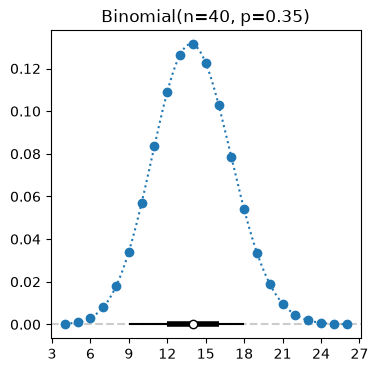

In [6]:
pz.Binomial(
    n=40,
    p=p_true,
).plot_pdf(
    figsize=(4, 4),
    interval="hdi",
    pointinterval=True,
    legend="title",
)

Compute the range that covers 50%, and 89% of probability density

In [7]:
pz.distributions.binomial.Binomial(
    n=40,
    p=p_true,
).hdi(mass=0.5), pz.distributions.binomial.Binomial(
    n=40,
    p=p_true,
).hdi(mass=0.89)

((12, 16), (9, 18))

------------------------------

## Running probabilistic analysis

### Configure PyTensor

In [8]:
pytensor.config.cxx = ""

### Create coin-toss data

Simulate tossing the coin 40 times

In [9]:
trials = 40
theta_real = 0.35
data = pz.Binomial(n=1, p=theta_real).rvs(trials)

In [10]:
heads = sum(data)
print(f"Count of Heads = {int(heads)}")

Count of Heads = 15


### Run model

We effectively say that our prior knowledge of the Probability of getting a Head on a coin toss is flat between 0 and 1 (a Beta distribution with $alpha = 1$, $beta = 1$ is a flat line)

In [11]:
with pm.Model() as our_first_model:
    th = pm.Beta("th", alpha=1, beta=1)
    y = pm.Bernoulli("y", p=th, observed=data)
    idata = pm.sample(
        1000,
    )  # cores=1

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [th]


Output()

The warning message above is alarming, but AI says ...

    No, this warning is generally not a critical problem on Windows. While the message warns of potential random crashes or deadlocks, this severe behavior primarily impacts Linux systems. On Windows, you can usually ignore this specific threadpoolctl warning, though it does mean multiple programs or libraries are competing to manage your CPU threads, which might slightly degrade performance

So I have decided to ignore the warning.  

The _idata_ output of the model run is a complex data structure

In [12]:
type(idata)

xarray.core.datatree.DataTree

In [13]:
idata

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:  (chain: 4, draw: 1000)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│       Data variables:
│           th       (chain, draw) float64 32kB 0.4016 0.4012 0.4012 ... 0.4077 0.3862
│       Attributes:
│           created_at:                 2026-09-22T04:26:24.969418+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.19109654426574707
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 1 1 1 2 ... 2 1 1 1 1
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 1.332 1.349 ... 1.452
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 1.286 1.286 ... 1.411
│           mean_tree_accept          (chain, draw) float64 32kB 0.9226 1.0 ... 1.0 1.0
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 0.0005086 ... 0.0009912
│           transformation_index      (chain, draw) int64 32kB 337 337 337 ... 337 337
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-09-22T04:26:24.949723+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Attributes:
│           created_at:                 2026-09-22T04:26:24.962789+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /observed_data
        Dimensions:  (y_dim_0: 40)
        Coordinates:
          * y_dim_0  (y_dim_0) int64 320B 0 1 2 3 4 5 6 7 8 ... 32 33 34 35 36 37 38 39
        Data variables:
            y        (y_dim_0) int64 320B 0 0 1 0 0 1 1 0 1 1 0 ... 0 0 0 0 1 1 0 0 1 1
        Attributes:
            created_at:                 2026-09-22T04:26:24.965991+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.1
            sample_dims:                []

### Visualize model results

Get a summary of the model run

We see our estimate is 0.31 (actual 30.35), with HDI range from 0.2 to 0.42


In [14]:
az.summary(idata, ci_kind="hdi", kind='stats')

,mean,sd,hdi89_lb,hdi89_ub
th,0.38,0.075,0.26,0.5



Old-fashioned statistics gives us:

In [15]:
p_freq = heads/40
ci_upper = p_freq+1.6*np.sqrt(p_freq*(1-p_freq)/40)
ci_lower = p_freq-1.6*np.sqrt(p_freq*(1-p_freq)/40)
print(f"Heads prob. estimated = {p_freq}. " +
      f"CI 89% range = {ci_lower:>5.2}<->{ci_upper:<5.2}")

Heads prob. estimated = 0.375. CI 89% range =  0.25<->0.5  


### Plotting results

Default plot from PyMC run.  We had four different random sampling processes running, and we can see the results from each.  The right plot is to provide visual evidence that the sampling was truely random

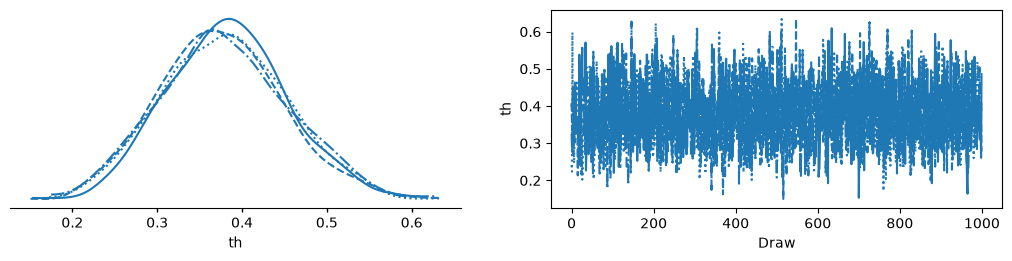

In [16]:
az.plot_trace_dist(idata)

We can get a combined probability distribution for the Prob. of a Head.

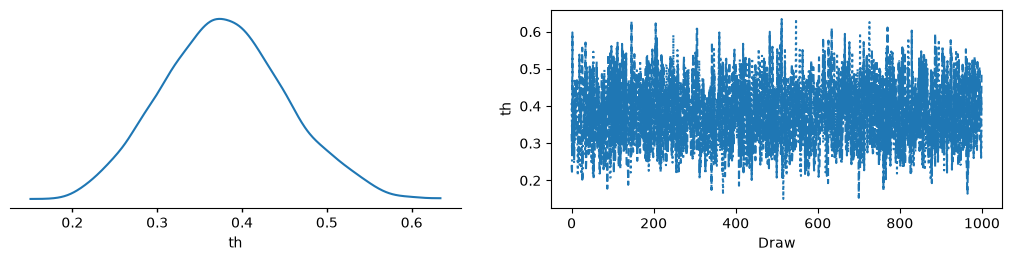

In [17]:
pc = az.plot_trace_dist(idata, combined=True, )
pc

We can adjust the figure parameters, in the _plot_trace_dist_ call, or get the Matplotlib _Figure_ or _Axes_ objects, and call their methods.

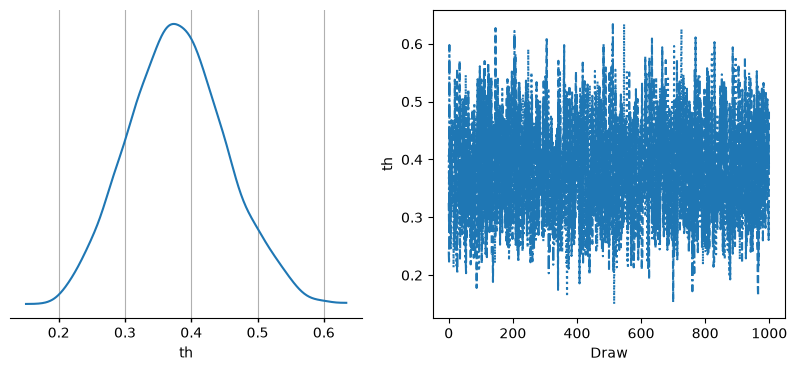

In [18]:
pc = az.plot_trace_dist(idata, combined=True, figure_kwargs={"figsize": (10, 4)})
pc.viz["figure"].item().get_axes()[0].grid(True, axis='both')
pc.show()

We can use a different call to show just the combined distribution (we add a grid for clarity)

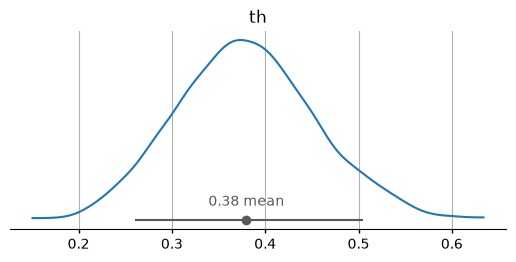

In [19]:
pc = az.plot_dist(idata)
pc.viz["figure"].item().get_axes()[0].grid(True, axis='both')
pc.show()

We can add a solid face to the curve

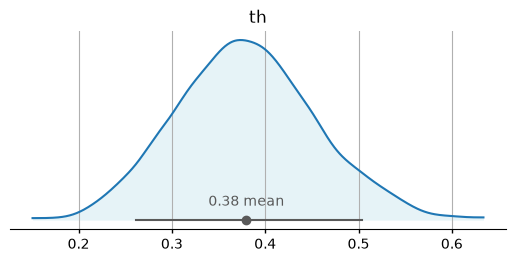

In [20]:
pc = az.plot_dist(idata, visuals={"face": {"color": "lightblue", "alpha": 0.3}})
pc.viz["figure"].item().get_axes()[0].grid(True, axis='both')
pc

We can also delete the Trace plot, and just show the Posterior curve, labelled by the chain that produced them

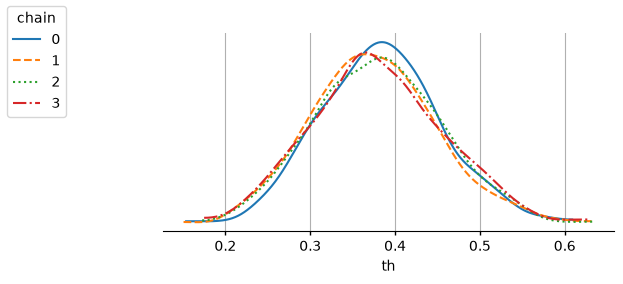

In [21]:
pc = az.plot_trace_dist(idata, aes={"color": ["chain"]}  )

# set grid visible on distributions plot
pc.viz["figure"].item().get_axes()[0].grid(True, axis='both')

# remove trace plot axes
pc.viz["figure"].item().delaxes(pc.viz["figure"].item().get_axes()[1])

# add legend at top left
pc.add_legend("chain", loc="upper left")
pc.show()

### Do we have a fair coin?

In this case we decide that any coin with a probability of a Head betwen 0.45 and 0.50 is "fair".  This regions is called the ROPE, Region of Practical Equivalence.  This this case, we decide we want really strong evidence that a coin is biased before declaring this fact (maybe the guy tossing the coin will take strong exception to being called a cheat!)

Se we ask for a plot of the ROPE, showing our ROPE, how much probability density is in the ROPE, and the spread of the region containing 99% of the  distribution of our PDF for the probability of Heads (just to recap, before we tossed our coins, we guessed a flat density from 0 to 1, now we have a density centered about a mean of 0.31)

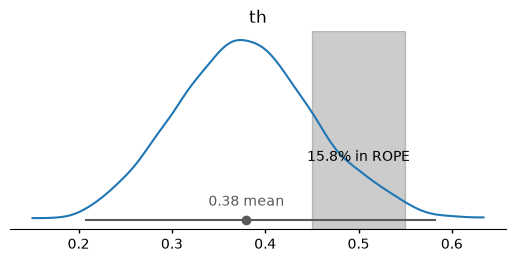

In [22]:
pc = az.plot_dist(idata, rope=(0.45, 0.55) ,  stats={"rope": {"ci_prob": 1}}, ci_prob=0.99)

pc.show()

Because there it least some overlap between our 99% interval, and the ROPE, we can't confidently declare (at the 99% level) that the coin is NOT FAIR.

In [23]:
pr = az.ci_in_rope(idata, rope=(0.45, 0.55), ci_prob=0.99 )

pr["th"].item()

15.980812926028781

If we relax our standard, and say that 90% now our acceptance criteria, we can declare the coin to be biased (even though our density for the probability of a Head still overlaps the ROPE to a small amount.

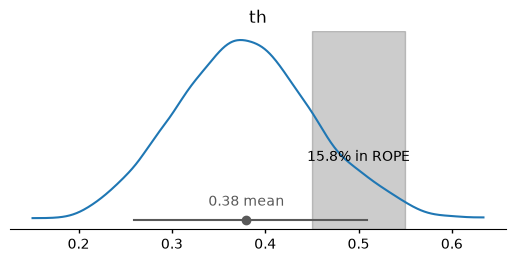

In [24]:
pc = az.plot_dist(idata, rope=(0.45, 0.55) ,  stats={"rope": {"ci_prob": 1}}, ci_prob=0.90)

pc.show()

In [25]:
pr = az.ci_in_rope(idata, rope=(0.45, 0.55), ci_prob=0.90 )

pr["th"].item()

13.107470147181338

--------------------

### Get summary of model run

We can get a summary of the results of fitting out model to our data.  The _mean_ and _median_ are close:  in the 89% range of these values, "hdi" = High Density Interval, "eti"= Equal Tail Interval, with equal density to left and right of density peak.

In [26]:
az.summary(idata, kind='stats', ci_kind="hdi")

,mean,sd,hdi89_lb,hdi89_ub
th,0.38,0.075,0.26,0.5


In [27]:
az.summary(idata, kind='stats_median',)

,median,mad,eti89_lb,eti89_ub
th,0.38,0.05,0.26,0.5


-----------------
### Get assessment of integrity of model run

In [28]:
problems = az.diagnose(idata)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


------------------

## More to come

This post is just an introduction to Bayes, in that we only used synthetic data to exercise our model.  More posts will cover more realistic situations

----------------------

## Reproducability

In [29]:
%load_ext watermark

In [30]:
%watermark

Last updated: 2026-09-22T14:26:27.476670+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [31]:
%watermark -h -iv -co 

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
preliz    : 0.28.0
pymc      : 6.3.1
pytensor  : 3.3.0
xarray    : 2026.7.0

